# Model 1 v2 – 05 Unseen-source test (v1 vs v2)
**Purpose:** Test v1 and v2 on image sources NEVER used in training: PneumoniaMNIST chest X-rays, OrganCMNIST CT,
RetinaMNIST retina photos, Flowers102, synthetic text documents, edge cases (inverted X-ray, simulated phone photo),
plus real photos in Research/UNSEEN_TEST/. The v1 test images are rebuilt exactly (same code, seed 7) and saved.
**Inputs:** outputs/model1/ (v1 model, v1 cache, v1 unseen predictions), outputs/model1_v2/ (v2 models), UNSEEN_TEST/
**Outputs:** outputs/model1_v2/unseen_suite_v1.npz, unseen_results_v1_vs_v2.csv, unseen_summary_v1_vs_v2.csv, figures

In [17]:
# ===== SETTINGS =====
from pathlib import Path
DRIVE_ROOT = Path('/content/drive/MyDrive/Research')
V1_DIR     = DRIVE_ROOT / 'outputs' / 'model1'
OUT_DIR    = DRIVE_ROOT / 'outputs' / 'model1_v2'
UNSEEN_DIR = DRIVE_ROOT / 'UNSEEN_TEST'
V1_MODEL   = V1_DIR / 'mobilenetv3_model1_best.pt'
V1_CACHE   = V1_DIR / 'cache_224.npz'
SUITE      = OUT_DIR / 'unseen_suite_v1.npz'

# real-world folders inside UNSEEN_TEST and the correct answer for each
UNSEEN_FOLDERS = {'Dental_xray_photos': 'X_RAY'}     # policy: a photo of an X-ray counts as an X-ray

In [18]:
!pip install -q medmnist timm
from google.colab import drive
drive.mount('/content/drive')
import numpy as np, pandas as pd, torch, torch.nn as nn, timm, io, shutil, matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter, ImageOps
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda


## Step 1 – Rebuild the v1 unseen test (code copied unchanged from v1, seed 7)
If unseen_suite_v1.npz already exists it is loaded (no downloads). If the Flowers102 server is down, flowers are
skipped but the random sequence is kept identical, so all other images are exactly the v1 images.

In [19]:
def to_224(im):                                   # v1 preprocessing, unchanged
    if im.mode in ('I;16', 'I;16B', 'I;16L', 'I', 'F'):
        a = np.array(im).astype(np.float32); a = (a - a.min()) / (a.max() - a.min() + 1e-6) * 255
        im = Image.fromarray(a.astype(np.uint8))
    im = im.convert('L'); w, h = im.size; s = max(w, h)
    c = Image.new('L', (s, s), 0); c.paste(im, ((s - w) // 2, (s - h) // 2))
    return np.array(c.resize((224, 224), Image.BILINEAR), dtype=np.uint8)

if SUITE.exists():
    s = np.load(SUITE, allow_pickle=True)
    imgs, groups, expected = s['images'], list(s['group']), list(s['expected'])
    print('Loaded saved unseen suite:', imgs.shape)
else:
    from medmnist import PneumoniaMNIST, RetinaMNIST, OrganCMNIST
    from torchvision import datasets
    shutil.copy(V1_CACHE, '/content/cache_224.npz')
    d = np.load('/content/cache_224.npz', allow_pickle=True)
    rng = np.random.default_rng(7)
    items = []
    def add(group, exp, pil_list):
        for im in pil_list: items.append((group, exp, to_224(im)))

    ds = PneumoniaMNIST(split='test', download=True, size=224, root='/content')
    add('chest_xray_PneumoniaMNIST', 'X_RAY', [Image.fromarray(ds.imgs[i]) for i in rng.choice(len(ds.imgs), 60, replace=False)])
    ds = OrganCMNIST(split='test', download=True, size=224, root='/content')
    add('CT_coronal_OrganCMNIST', 'NON_XRAY', [Image.fromarray(ds.imgs[i]) for i in rng.choice(len(ds.imgs), 50, replace=False)])
    ds = RetinaMNIST(split='test', download=True, size=224, root='/content')
    add('retina_photo_RetinaMNIST', 'NON_XRAY', [Image.fromarray(ds.imgs[i]) for i in rng.choice(len(ds.imgs), 40, replace=False)])
    try:
        fl = datasets.Flowers102('/content/flowers', split='test', download=True)
        add('flower_photo_Flowers102', 'NON_XRAY', [fl[int(i)][0] for i in rng.choice(len(fl), 40, replace=False)])
    except Exception as e:
        print('Flowers102 server error – skipping flowers, keeping the random sequence identical:', e)
        rng.choice(6149, 40, replace=False)    # same random draw as v1 (Flowers test split = 6,149 images)

    words = ('patient report radiology hospital clinic name date result normal findings '
             'impression history examination left right signature doctor ward').split()
    docs = []
    for _ in range(20):
        im = Image.new('L', (600, 800), 255); dr = ImageDraw.Draw(im); yy = 40
        while yy < 760:
            dr.text((40, yy), ' '.join(rng.choice(words, rng.integers(4, 9))), fill=0); yy += int(rng.integers(18, 30))
        docs.append(im)
    add('text_document_synthetic', 'NON_XRAY', docs)

    X1, y1, split1 = d['X'], d['y'], d['split']
    pick = rng.choice(np.where((split1 == 'test') & (y1 == 1))[0], 20, replace=False)
    for j in pick:
        items.append(('EDGE_inverted_xray', 'unclear', 255 - X1[j]))

    def fake_phone_photo(img):
        xr = Image.fromarray(img).resize((300, 300)).convert('RGB')
        bg = tuple(int(v) for v in rng.integers(90, 200, 3))
        canvas = Image.new('RGB', (420, 420), bg)
        screen = Image.new('RGB', (340, 340), (20, 20, 20)); screen.paste(xr, (20, 20))
        canvas.paste(screen, (40, 40))
        canvas = canvas.rotate(float(rng.uniform(-12, 12)), resample=Image.BILINEAR, fillcolor=bg)
        a = np.array(canvas).astype(np.float32)
        a = np.clip(a * np.array([1.05, 1.0, 0.9]) + np.linspace(0, 60, 420)[None, :, None], 0, 255)
        im = Image.fromarray(a.astype(np.uint8)).filter(ImageFilter.GaussianBlur(1.2))
        buf = io.BytesIO(); im.save(buf, 'JPEG', quality=60); buf.seek(0)
        return Image.open(buf)
    for j in pick:
        items.append(('EDGE_photo_of_xray_simulated', 'unclear', to_224(fake_phone_photo(X1[j]))))

    imgs = np.stack([it[2] for it in items]); groups = [it[0] for it in items]; expected = [it[1] for it in items]
    np.savez_compressed(SUITE, images=imgs, group=np.array(groups), expected=np.array(expected))
    print('Rebuilt and saved unseen suite:', imgs.shape, '->', SUITE)

print(pd.Series(groups).value_counts().to_string())

Loaded saved unseen suite: (250, 224, 224)
chest_xray_PneumoniaMNIST       60
CT_coronal_OrganCMNIST          50
retina_photo_RetinaMNIST        40
flower_photo_Flowers102         40
text_document_synthetic         20
EDGE_inverted_xray              20
EDGE_photo_of_xray_simulated    20


In [20]:
def prep_v2(im):                                  # same preprocessing as the v2 training data
    im = ImageOps.exif_transpose(im)
    if im.mode == 'P': im = im.convert('RGBA')
    if im.mode in ('RGBA', 'LA'):
        bg = Image.new('RGBA', im.size, (0, 0, 0, 255)); im = Image.alpha_composite(bg, im.convert('RGBA'))
    return to_224(im)

n_v1 = len(groups)                                 # the first n_v1 images = the v1 suite
all_imgs, all_groups, all_expected = list(imgs), list(groups), list(expected)
for folder, exp in UNSEEN_FOLDERS.items():
    files = sorted(p for p in (UNSEEN_DIR / folder).glob('*') if p.is_file())
    for p in files:
        with Image.open(p) as im:
            all_imgs.append(prep_v2(im)); all_groups.append(f'REAL_{folder}'); all_expected.append(exp)
    print(f'{folder}: {len(files)} images (expected {exp})')
all_imgs = np.stack(all_imgs)
print('Total unseen images:', len(all_imgs))

Dental_xray_photos: 11 images (expected X_RAY)
Total unseen images: 261


## Step 2 – Predict with v1, v2 MobileNetV3, v2 DeiT-Small and v2 ensemble
Check: v1 predictions on the rebuilt suite must match the predictions saved by v1 (proves the suite is identical).

In [21]:
from torchvision.models import mobilenet_v3_large
IMNET = ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

def tv_mobilenet(state_dict):
    m = mobilenet_v3_large(); m.classifier[3] = nn.Linear(m.classifier[3].in_features, 2)
    m.load_state_dict(state_dict); return m.eval().to(device)

ck  = torch.load(OUT_DIR / 'mobilenetv3_model1v2_best.pt', map_location=device)
ckd = torch.load(OUT_DIR / 'deit_small_model1v2_best.pt', map_location=device)
deit = timm.create_model(ckd['timm_name'], pretrained=False, num_classes=2)
deit.load_state_dict(ckd['state_dict']); deit.eval().to(device)
EVAL = {'v1 MobileNetV3': (tv_mobilenet(torch.load(V1_MODEL, map_location=device)), *IMNET),
        'v2 MobileNetV3': (tv_mobilenet(ck['state_dict']), ck['mean'], ck['std']),
        'v2 DeiT-Small':  (deit, ckd['mean'], ckd['std'])}

@torch.no_grad()
def p_xray(model, mean, std, arr):
    mean = torch.tensor(mean).view(1, 3, 1, 1).to(device); std = torch.tensor(std).view(1, 3, 1, 1).to(device)
    out = []
    for k in range(0, len(arr), 64):
        t = torch.from_numpy(arr[k:k+64]).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(device)
        out.append(torch.softmax(model((t - mean) / std), 1)[:, 1].cpu().numpy())
    return np.concatenate(out)

res = pd.DataFrame({'group': all_groups, 'expected': all_expected})
for name, (m, mean, std) in EVAL.items():
    res[name] = p_xray(m, mean, std, all_imgs)
res['v2 Ensemble'] = (res['v2 MobileNetV3'] + res['v2 DeiT-Small']) / 2

old = pd.read_csv(V1_DIR / 'unseen_test_predictions.csv')
old_cmp = old[old.group.isin(set(groups))].prob_xray.values      # skips flowers if they are missing
print('Reproduction check – max difference vs v1 saved predictions:',
      np.abs(res['v1 MobileNetV3'].values[:n_v1] - old_cmp).max().round(4))
res.to_csv(OUT_DIR / 'unseen_results_v1_vs_v2.csv', index=False)

Reproduction check – max difference vs v1 saved predictions: 0.0


In [22]:
MODELS_ = ['v1 MobileNetV3', 'v2 MobileNetV3', 'v2 DeiT-Small', 'v2 Ensemble']
rows = []
for (g, exp), sub in res.groupby(['group', 'expected'], sort=False):
    row = {'group': g, 'expected': exp, 'n': len(sub)}
    for m in MODELS_:
        acc_x = (sub[m] >= 0.5).mean()                       # share predicted X-ray
        row[m] = round(100 * (acc_x if exp == 'X_RAY' else 1 - acc_x if exp == 'NON_XRAY' else acc_x), 1)
    rows.append(row)
table = pd.DataFrame(rows)
print('Values = % CORRECT (for "unclear" edge cases: % accepted as X-ray)\n')
print(table.to_string(index=False))

known = res[res.expected != 'unclear']
print('\nOverall correct on known groups (n=%d):' % len(known))
for m in MODELS_:
    print(f'  {m:15s}: {((known[m] >= 0.5) == (known.expected == "X_RAY")).mean():.1%}')
table.to_csv(OUT_DIR / 'unseen_summary_v1_vs_v2.csv', index=False)

Values = % CORRECT (for "unclear" edge cases: % accepted as X-ray)

                       group expected  n  v1 MobileNetV3  v2 MobileNetV3  v2 DeiT-Small  v2 Ensemble
   chest_xray_PneumoniaMNIST    X_RAY 60            65.0           100.0          100.0        100.0
      CT_coronal_OrganCMNIST NON_XRAY 50           100.0            94.0           96.0         94.0
    retina_photo_RetinaMNIST NON_XRAY 40            77.5            97.5           87.5         95.0
     flower_photo_Flowers102 NON_XRAY 40            97.5            92.5           92.5         92.5
     text_document_synthetic NON_XRAY 20           100.0           100.0          100.0        100.0
          EDGE_inverted_xray  unclear 20            95.0           100.0          100.0        100.0
EDGE_photo_of_xray_simulated  unclear 20           100.0            95.0          100.0        100.0
     REAL_Dental_xray_photos    X_RAY 11            90.9            81.8          100.0        100.0

Overall correct on kno

v2 ensemble mistakes: 8


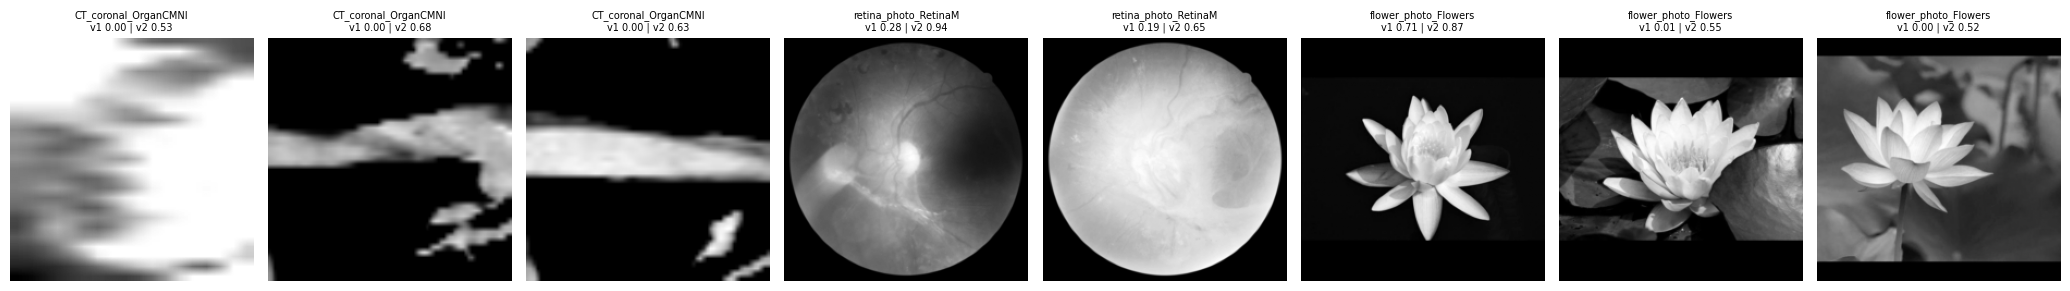

In [23]:
wrong = res[(res.expected != 'unclear') & ((res['v2 Ensemble'] >= 0.5) != (res.expected == 'X_RAY'))]
print('v2 ensemble mistakes:', len(wrong))
if len(wrong):
    show = wrong.head(12)
    fig, axes = plt.subplots(1, len(show), figsize=(2.6 * len(show), 3.2)); axes = np.atleast_1d(axes)
    for ax, (i, r) in zip(axes, show.iterrows()):
        ax.imshow(all_imgs[i], cmap='gray'); ax.axis('off')
        ax.set_title(f'{r.group[:20]}\nv1 {r["v1 MobileNetV3"]:.2f} | v2 {r["v2 Ensemble"]:.2f}', fontsize=7)
    plt.tight_layout(); plt.savefig(OUT_DIR / 'unseen_v2_mistakes.png', dpi=120, bbox_inches='tight'); plt.show()

### Idea: three-way decision instead of yes/no
Most remaining v2 mistakes have probabilities near 0.5. Gate rule: p ≥ 0.7 → accept as X-ray, p < 0.3 → reject,
0.3–0.7 → "uncertain – please upload a clearer X-ray / human check". Band fixed in advance (symmetric default),
NOT tuned on this test set.

In [24]:
LOW, HIGH = 0.3, 0.7
y_true = (known.expected == 'X_RAY').values
for m in MODELS_:
    p = known[m].values
    acc, rej = p >= HIGH, p < LOW
    unc = ~acc & ~rej
    wrong = (acc & ~y_true) | (rej & y_true)
    print(f'{m:15s}: decided {(~unc).mean():5.1%} | wrong decisions {wrong.sum():2d} | sent to "uncertain" {unc.sum():2d}')

v1 MobileNetV3 : decided 86.9% | wrong decisions 15 | sent to "uncertain" 29
v2 MobileNetV3 : decided 96.4% | wrong decisions  6 | sent to "uncertain"  8
v2 DeiT-Small  : decided 97.3% | wrong decisions  7 | sent to "uncertain"  6
v2 Ensemble    : decided 94.1% | wrong decisions  2 | sent to "uncertain" 13


## Summary – Model 1 v2 (unseen-source test, 221 known + 40 edge-case images)
Reproduction check: v1 predictions on the rebuilt suite = saved v1 predictions (max diff 0.0) → identical test.
| Group | v1 | v2 MobileNetV3 | v2 DeiT | v2 Ensemble |
|---|---|---|---|---|
| Chest X-ray (PneumoniaMNIST) | 65.0 | 100 | 100 | 100 |
| CT (OrganCMNIST) | 100 | 94.0 | 96.0 | 94.0 |
| Retina photo | 77.5 | 97.5 | 87.5 | 95.0 |
| Flower photo | 97.5 | 92.5 | 92.5 | 92.5 |
| Text document | 100 | 100 | 100 | 100 |
| Real dental X-ray photos (11) | 90.9 | 81.8 | 100 | 100 |
| **Overall (known)** | **85.5** | **95.9** | **95.5** | **96.4** |
Edge cases (policy open): inverted X-ray accepted 100% (v2), simulated phone photo 95–100%.
Fixed: chest rejection, retina acceptance. Trade-off: a few low-res CT crops / bright flowers on dark backgrounds
now accepted, mostly with p 0.5–0.7.
**Three-way gate** (≥0.7 X-ray, <0.3 not X-ray, else "uncertain – please check"): v2 ensemble = 2 wrong decisions,
13 uncertain (5.9%); v1 = 15 wrong, 29 uncertain.
**Final Model 1 = v2 ensemble (MobileNetV3 + DeiT-Small) with three-way decision.**
Limitations: band and ensemble choice informed by this test → confirm on a new unseen set; dental = 1 patient,
~3–4 X-rays; inverted / photographed X-ray policy to be agreed with the team.